## This is a testing notebook for transformation algorithm, see the model training part and the commented code segments for more algorithms to try!

### KNN regression, red wine dataset, test

**Even though this is a classification dataset, the target is ordinal (3-8, bad -> excellent), which means we can also attempt regression models with it.**

In [109]:
# usual imports in a classic ML pipeline for Regression
# pip install numpy
# pip install pandas
# pip install seaborn
# pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# import pipelines, SVM etc.
from sklearn.model_selection import train_test_split
from sklearn import metrics, svm

# regression
from sklearn.neighbors import KNeighborsRegressor

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler


In [110]:
# load the data
df = pd.read_csv("winequality-red.csv")

# let's quickly see the first 5 rows of data
df.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


In [111]:
df['quality'].value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

If your dataset does not have any binary variables => remove/disable the code cell below.

In [112]:
df.duplicated().sum()

np.int64(240)

In [113]:
df = df.drop_duplicates()

In [114]:
df['quality'].value_counts()

quality
5    577
6    535
7    167
4     53
8     17
3     10
Name: count, dtype: int64

### STEP 3: Data is good to go (all numbers) => train model etc.

In [115]:
# first step, we split our data into SUPPORT variables and the TARGET variable
# X => support variables, y => target variable

# X => list of support variables the model uses 
# while predicting the target variable with the model
X = df.drop("quality", axis=1)

# our target variable is y
y = df['quality']

**IMPORTANT WHEN OPTIMIZING PARAMETERS!**

Always lock down randomness in your algorithm and data so that your baseline remains the same. If you don't do this, you never know if the model improved because of the parameters or just sheer luck!

Here we only lock down train/test-split. We usually also lock down NumPy random seed + others!

In [116]:
# secondly, train/test -split with scikit-learn's helper function
# 0.3 for testing => 30% of data is reserved for testing purposes
# and based on that => it's deduced that 70% will be in the training data

# you can also define the random state, which is sometimes useful
# if you want to "lock down" all the randomness in order to get same results every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=19)

Based on iterations, best k-value is this:
20


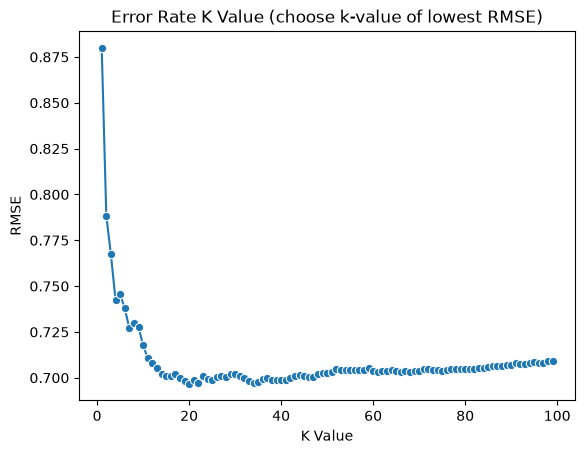

In [117]:
# REGRESSION VERSION
# adjust this to 50 or even 150 if you have lots of data rows
max_iterations = 100

# list to save the error values in the loop
error = []

# the default metric in scikit-learn
metric_selection = "minkowski"
weight_selection = "uniform"
algorithm_selection = "auto"

# Calculating error for K values between 1 and 40
for i in range(1, max_iterations):

    # try with current k-value, train the model and make a test prediction
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=i, metric=metric_selection, weights=weight_selection, algorithm=algorithm_selection))
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    
    # save the error value for this k-value
    error.append(np.sqrt(metrics.mean_squared_error(y_test, pred_i)))
    
# plot all the k-values and their error values
sns.lineplot(x=range(1, max_iterations), y=error, marker='o')
plt.title('Error Rate K Value (choose k-value of lowest RMSE)')
plt.xlabel('K Value')
plt.ylabel('RMSE')

# choose best k-value based on metrics
# we have to add +1 to k-value, since argmin() returns an index
# which starts from 0, but k-values start from 1
print("Based on iterations, best k-value is this:")
k_value = np.argmin(error) + 1
print(k_value)

### Build the pipeline/model for KNN regressor

### With TransformedTargetRegressor, we can easily attempt using a transformation algorithm with our model!

In [118]:
# create the model and train it with the data
# use pipeline to scale the X-values automatically with StandardScaler

from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.preprocessing import QuantileTransformer
from sklearn.preprocessing import RobustScaler

# TECHNICALLY you don't even have to use scaler for X (StandardScaler here)
# but it doesn't hurt the model either. it's just more practical
# to have the scaler already implemented in case we try different algorithms on the go
# model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k_value, metric=metric_selection))
# model = TransformedTargetRegressor(
#     regressor=make_pipeline(
#         StandardScaler(),
#         KNeighborsRegressor(
#             n_neighbors=k_value,
#             metric=metric_selection,
#             weights=weight_selection,
#             algorithm=algorithm_selection
#         )
#     ),
#     transformer=PowerTransformer(method='yeo-johnson')
# )


model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(
            n_neighbors=k_value,
            metric=metric_selection,
            weights=weight_selection,
            algorithm=algorithm_selection
        )
    ),
    transformer=PowerTransformer(method='yeo-johnson')
)

model.fit(X_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step....int64(20)))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",PowerTransformer()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,11
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step....int64(20)))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,PowerTransformer,PowerTransformer()
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsregressor', ...)]"


In [119]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = model.predict(X_test)

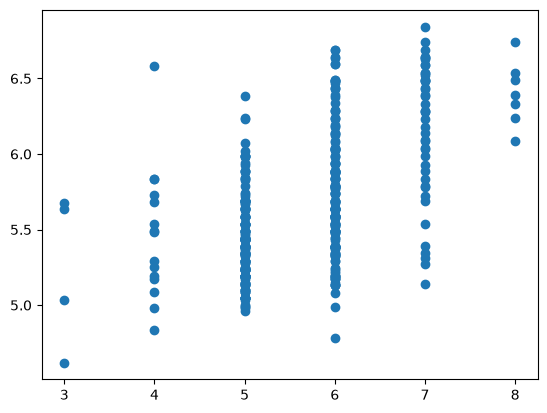

In [120]:
# let's plot how far the predictions are from the real target values (y)
# in the test dataset

# if the values follow a diagonal line (from bottom left to top right)
# => we have good predictions with the model
# we basically compare the predicted values to the actual true values 
# and compare the differences
plt.scatter(y_test, predictions)
plt.show()

In [121]:
# MAE = Mean average error
mae = metrics.mean_absolute_error(y_test, predictions)
print("MAE:")
print(f"{round(mae, 2)} quality level")

# MSE = Mean squared error
mse = metrics.mean_squared_error(y_test, predictions)
print("\nMSE:")
print(f"{round(mse, 2)} quality levels^2")

# RMSE = Root Mean Squared Error
rmse = np.sqrt(mse)
print("\nRMSE:")
print(f"{round(rmse, 2)} quality level")

# R-square (or R2) - how well the model describes the original dataset
# 1 => model describes the data perfectly
# 0 => model doesn't describe the data at all
r2 = metrics.r2_score(y_test, predictions)
print("\nR-squared:")
print(f"{round(r2, 2)}")


MAE:
0.54 quality level

MSE:
0.48 quality levels^2

RMSE:
0.7 quality level

R-squared:
0.3


In [ ]:
# these are the original metrics,
# model improved ever so slightly with MSE!

# MAE:
# 0.54 quality level

# MSE:
# 0.49 quality levels^2

# RMSE:
# 0.7 quality level

# R-squared:
# 0.3

C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_10548\2920752686.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test - predictions))


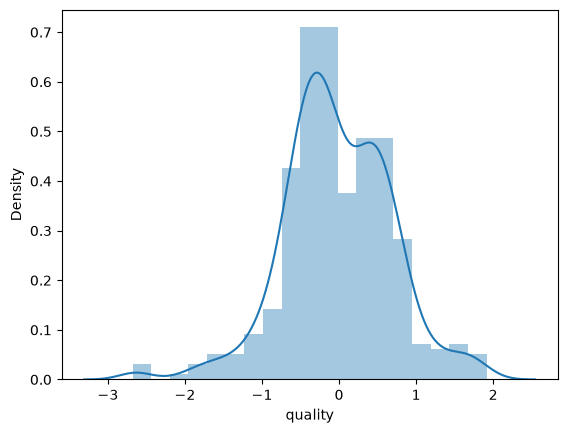

In [123]:
# if the prediction distribution is far from standard normal distritbuion
# then the model is not probably good enough
# distplot is deprecated and will be removed in future seaborn versions
# but not direct replacement has been created so far
sns.distplot((y_test - predictions))
plt.show()
plt.close()

In [124]:
X.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='str')

In [125]:
# map all the variables from the user
# into a Python dictionary
# the variable names have to match with the original dataset
tester_row = {
    'fixed acidity': 7.4, 
    'volatile acidity': 0.7, 
    'citric acid': 0.0, 
    'residual sugar': 1.9,
    'chlorides': 0.076, 
    'free sulfur dioxide': 11.0, 
    'total sulfur dioxide': 34.0, 
    'density': 0.9978,
    'pH': 3.51, 
    'sulphates': 0.56,
    'alcohol': 9.4
}

# convert to pandas-format
tester_row = pd.DataFrame([tester_row])

**No need to invert scaling here, Pipeline + TransformedTargetRegressor scale X/y -automatically!**

In [126]:
# get the output/result/answer from the model
# based on the user's new data (from above code cell)
result = model.predict(tester_row)[0]

print()
print(f"Predicted quality level for this red wine:")
print(f"{round(float(result), 2)} quality level")

import math
lower_level = math.floor(result)
upper_level = math.ceil(result)

print(f"Quality level is in range: {lower_level} - {upper_level}")



Predicted quality level for this red wine:
5.19 quality level
Quality level is in range: 5 - 6


The biggest problem of the red wine dataset is the fact that it's very difficult to differentiate between qualities 5 and 6. So having an output where "Quality level is in range: 5 - 6", is not very useful.

The raw output "5.2 quality level" WOULD BE USEFUL, if the error metrics were better (R2 of 0.3 is not very good, and RMSE is too big too).